# Setup

In [43]:
from statasetup import *

In [66]:
%%stata
use "Datasets\asg1\PlannedEnv_4countries.dta",clear
*drop missing values
drop if intention == . | perc_beh_cont == . | behavior == .


. use "Datasets\asg1\PlannedEnv_4countries.dta",clear

. *drop missing values
. drop if intention == . | perc_beh_cont == . | behavior == .
(0 observations deleted)

. 


# Regression 

## Step 1 - _general setup_
Create **dummy variables** by using a command the `tabulate name_of_the_Variable, generate(name_root_dummy_var)` command that facilitates the process.

Also do ensure **missing values are not present**

In [95]:
%%stata
* No missing values so we can proceed to creating the dummy variables
list behavior id country if behavior >=.
* However country variable appears to be not free of missing values at the beginning...(exclusion required)
list behavior id country if country >=.
drop if country ==.



. * No missing values so we can proceed to creating the dummy variables
. list behavior id country if behavior >=.

. * However country variable appears to be not free of missing values at the be
> ginning...(exclusion required)
. list behavior id country if country >=.

     +------------------------------+
     |    behavior     id   country |
     |------------------------------|
178. | 2.404255319   1178         . |
     +------------------------------+

. drop if country ==.
(1 observation deleted)

. 


In [96]:
%%stata
tabulate country, generate(country_dummy)


    country |      Freq.     Percent        Cum.
------------+-----------------------------------
      Spain |        199       24.88       24.88
      India |        200       25.00       49.88
         US |        200       25.00       74.88
     Mexico |        201       25.12      100.00
------------+-----------------------------------
      Total |        800      100.00


Keep in mind that the creation of these dummy variables is verifiable by identifying their corresponding means in the dummy variables respective summary tables 

In [97]:
%%stata
sum country_dummy1
sum country_dummy2
sum country_dummy3
sum country_dummy4

rename country_dummy1 spain_dummy
rename country_dummy2 India_dummy
rename country_dummy3 US_dummy
rename country_dummy4 Mexico_dummy


. sum country_dummy1

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
country_du~1 |        800      .24875     .432559          0          1

. sum country_dummy2

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
country_du~2 |        800         .25    .4332836          0          1

. sum country_dummy3

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
country_du~3 |        800         .25    .4332836          0          1

. sum country_dummy4

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
country_du~4 |        800      .25125    .4340033          0          1

. 
. rename country_dummy1 spain_dummy

. r

## Step 2 - _run reg_

**Do not include the referenced category/group**

In [98]:
%%stata
reg behavior India_dummy US_dummy Mexico_dummy


      Source |       SS           df       MS      Number of obs   =       800
-------------+----------------------------------   F(3, 796)       =    127.52
       Model |  26.1825212         3  8.72750708   Prob > F        =    0.0000
    Residual |  54.4800296       796  .068442248   R-squared       =    0.3246
-------------+----------------------------------   Adj R-squared   =    0.3220
       Total |  80.6625508       799  .100954381   Root MSE        =    .26161

------------------------------------------------------------------------------
    behavior | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
 India_dummy |  -.0593378   .0261943    -2.27   0.024    -.1107559   -.0079197
    US_dummy |  -.4632387   .0261943   -17.68   0.000    -.5146568   -.4118206
Mexico_dummy |  -.2472295   .0261618    -9.45   0.000    -.2985838   -.1958753
       _cons |   2.666953   .0185454   143.81   0.

Learn about how **the referenced group is being changed**. In this case, we just _shuffle around_ the formerly referenced category (i.e. Spain) so that its name is coded explicitly in the code syntax while Indian's are left out (and perceived by the software as the referenced category)

Furthertmore, as a post-hoc analysis one can use `test` command to retrieve the F-value corresponding to indian's-spanish's.
**Note that when comparing to groups (or when the df of the nominator of
the F-test is 1), t equals the square root of F**


. * we either run a new regression with a different country as the reference co
> untry
. reg behavior spain_dummy US_dummy Mexico_dummy

      Source |       SS           df       MS      Number of obs   =       800
-------------+----------------------------------   F(3, 796)       =    127.52
       Model |  26.1825212         3  8.72750708   Prob > F        =    0.0000
    Residual |  54.4800296       796  .068442248   R-squared       =    0.3246
-------------+----------------------------------   Adj R-squared   =    0.3220
       Total |  80.6625508       799  .100954381   Root MSE        =    .26161

------------------------------------------------------------------------------
    behavior | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
 spain_dummy |   .0593378   .0261943     2.27   0.024     .0079197    .1107559
    US_dummy |  -.4039009   .0261615   -15.44   0.000    -.4552545   -

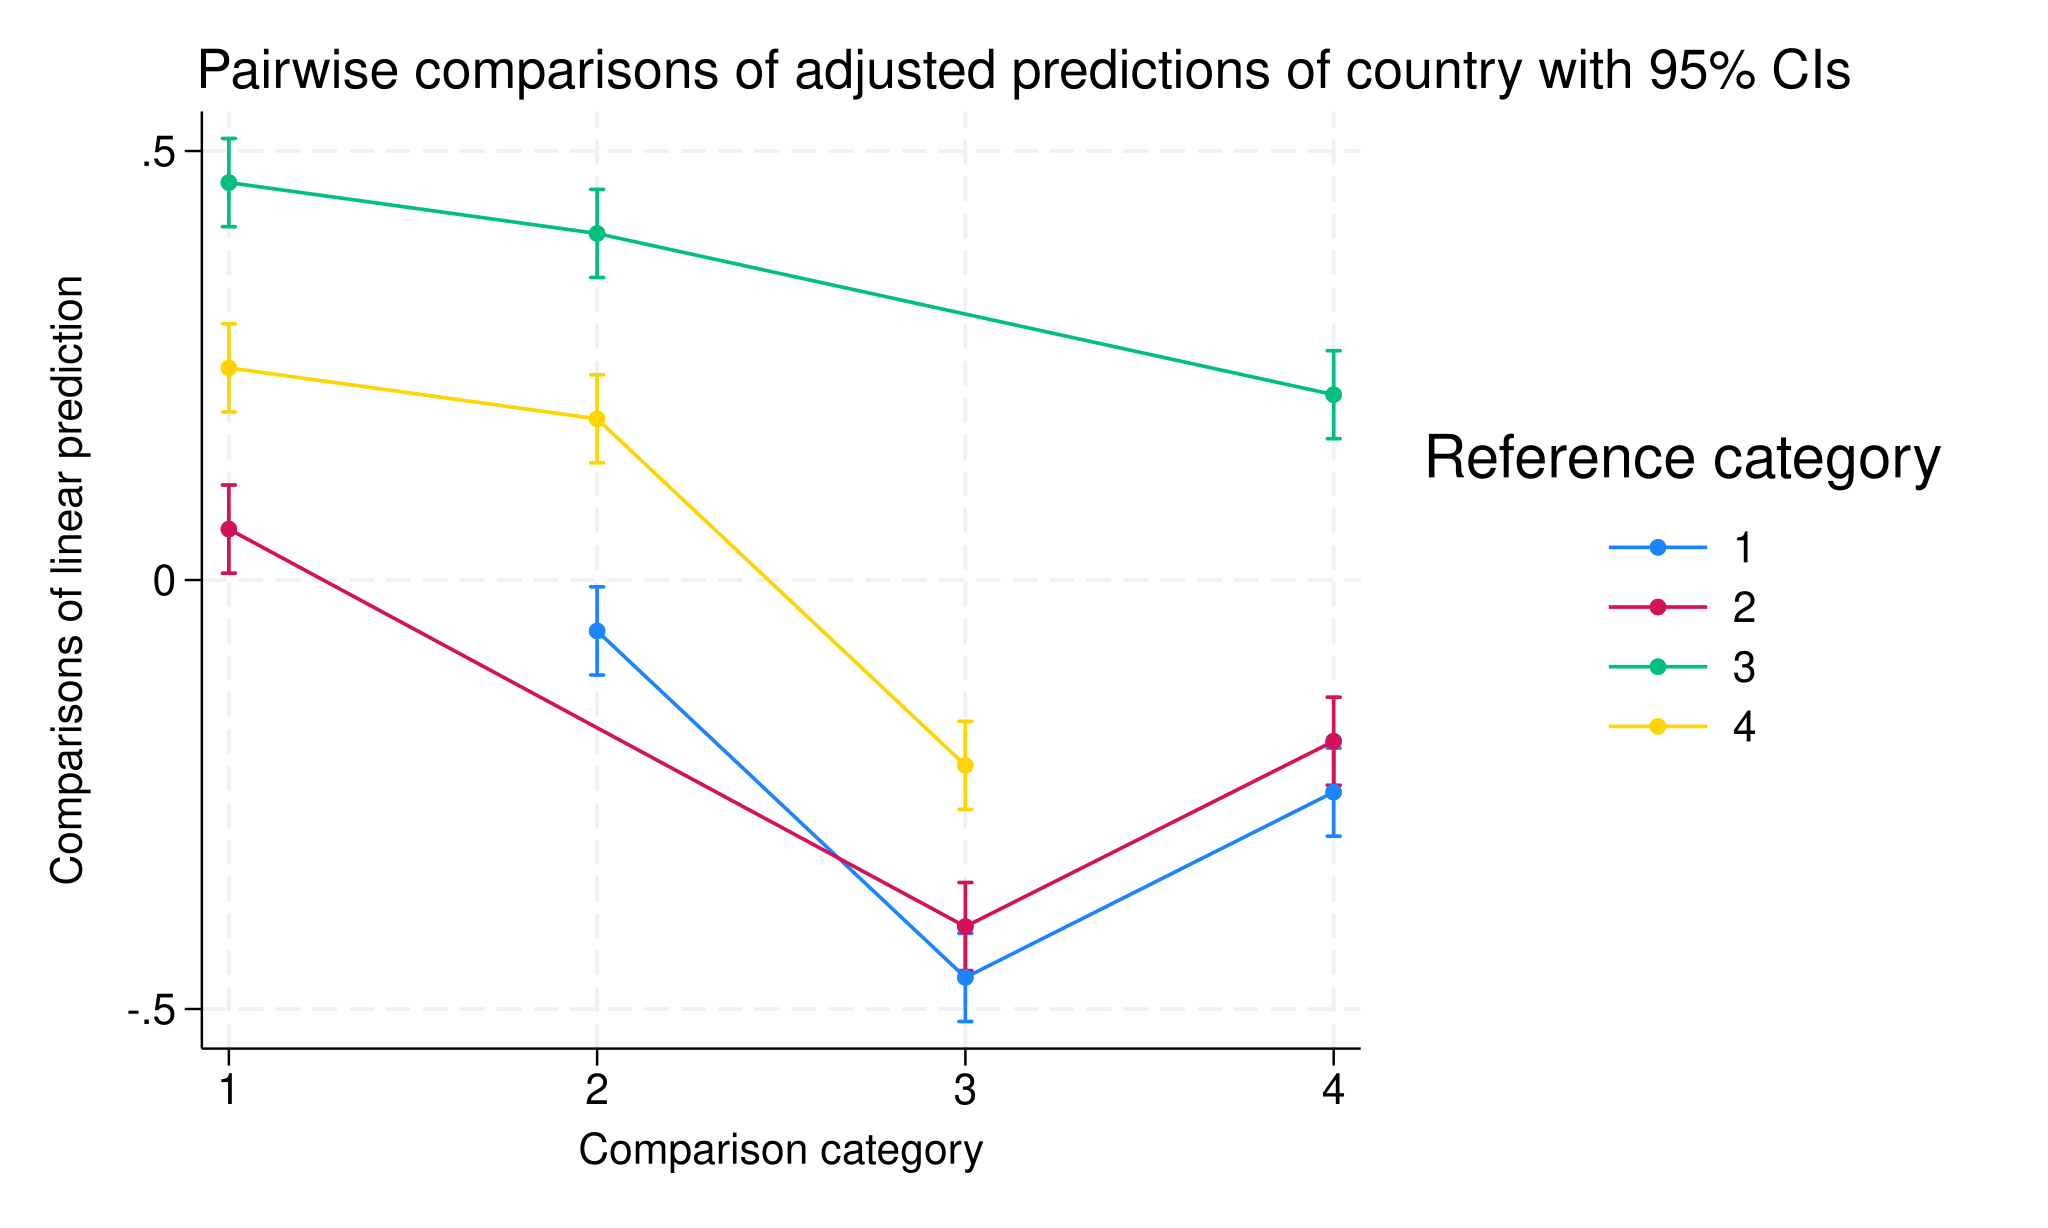

In [99]:
%%stata
* we either run a new regression with a different country as the reference country
reg behavior spain_dummy US_dummy Mexico_dummy

* or use the test postestimation command after the original regression
* This way you do not need to run different regressions to compare each country with each other
reg behavior India_dummy US_dummy Mexico_dummy
test _b[India_dummy]=_b[Mexico_dummy]  // referes to the estimated regression weight of the specified predictor

*or use the margins postestimation command to all possible paired comparisons
reg behavior i.country
margins country, pwcompare(effects) 
marginsplot

## Step 3 - _unveil how much of an explanation a certain variable does in relation to the independent variable_ using corelation and its square root
*using `pwcorr` one can determine correlation... or test for multicolinearity*

*using `scatter` to display the association between IV and DV*

*using as an option to the reg the `vif()`*

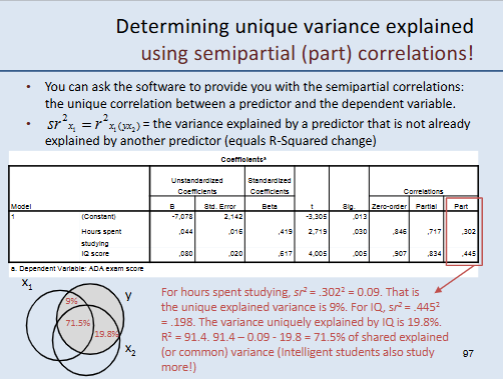

In [139]:
%%stata
* basic function setup
pwcorr intention behavior
* setup that features both, the critical value level and the p-value 
* Same as above, but use Bonferroni-adjusted significance levels
pwcorr intention behavior, sig star(0.5) bonferroni
* or to test in bulk amongst predictors or in relation with DP
pwcorr attitude social_norms perc_beh_cont, sig star(0.5) bonferroni
pwcorr behavior attitude social_norms perc_beh_cont, sig star(0.5) bonferroni
pwcorr intention attitude social_norms perc_beh_cont, sig star(0.5) bonferroni



. * basic function setup
. pwcorr intention behavior

             | intent~n behavior
-------------+------------------
   intention |   1.0000 
    behavior |   0.5325   1.0000 

. * setup that features both, the critical value level and the p-value 
. * Same as above, but use Bonferroni-adjusted significance levels
. pwcorr intention behavior, sig star(0.5) bonferroni

             | intent~n behavior
-------------+------------------
   intention |   1.0000 
             |
             |
    behavior |   0.5325*  1.0000 
             |   0.0000
             |

. * or to test in bulk amongst predictors or in relation with DP
. pwcorr attitude social_norms perc_beh_cont, sig star(0.5) bonferroni

             | attitude social~s perc_b~t
-------------+---------------------------
    attitude |   1.0000 
             |
             |
social_norms |   0.3060*  1.0000 
             |   0.0000
             |
perc_beh_c~t |   0.4348*  0.4744*  1.0000 
             |   0.0000   0.0000
     

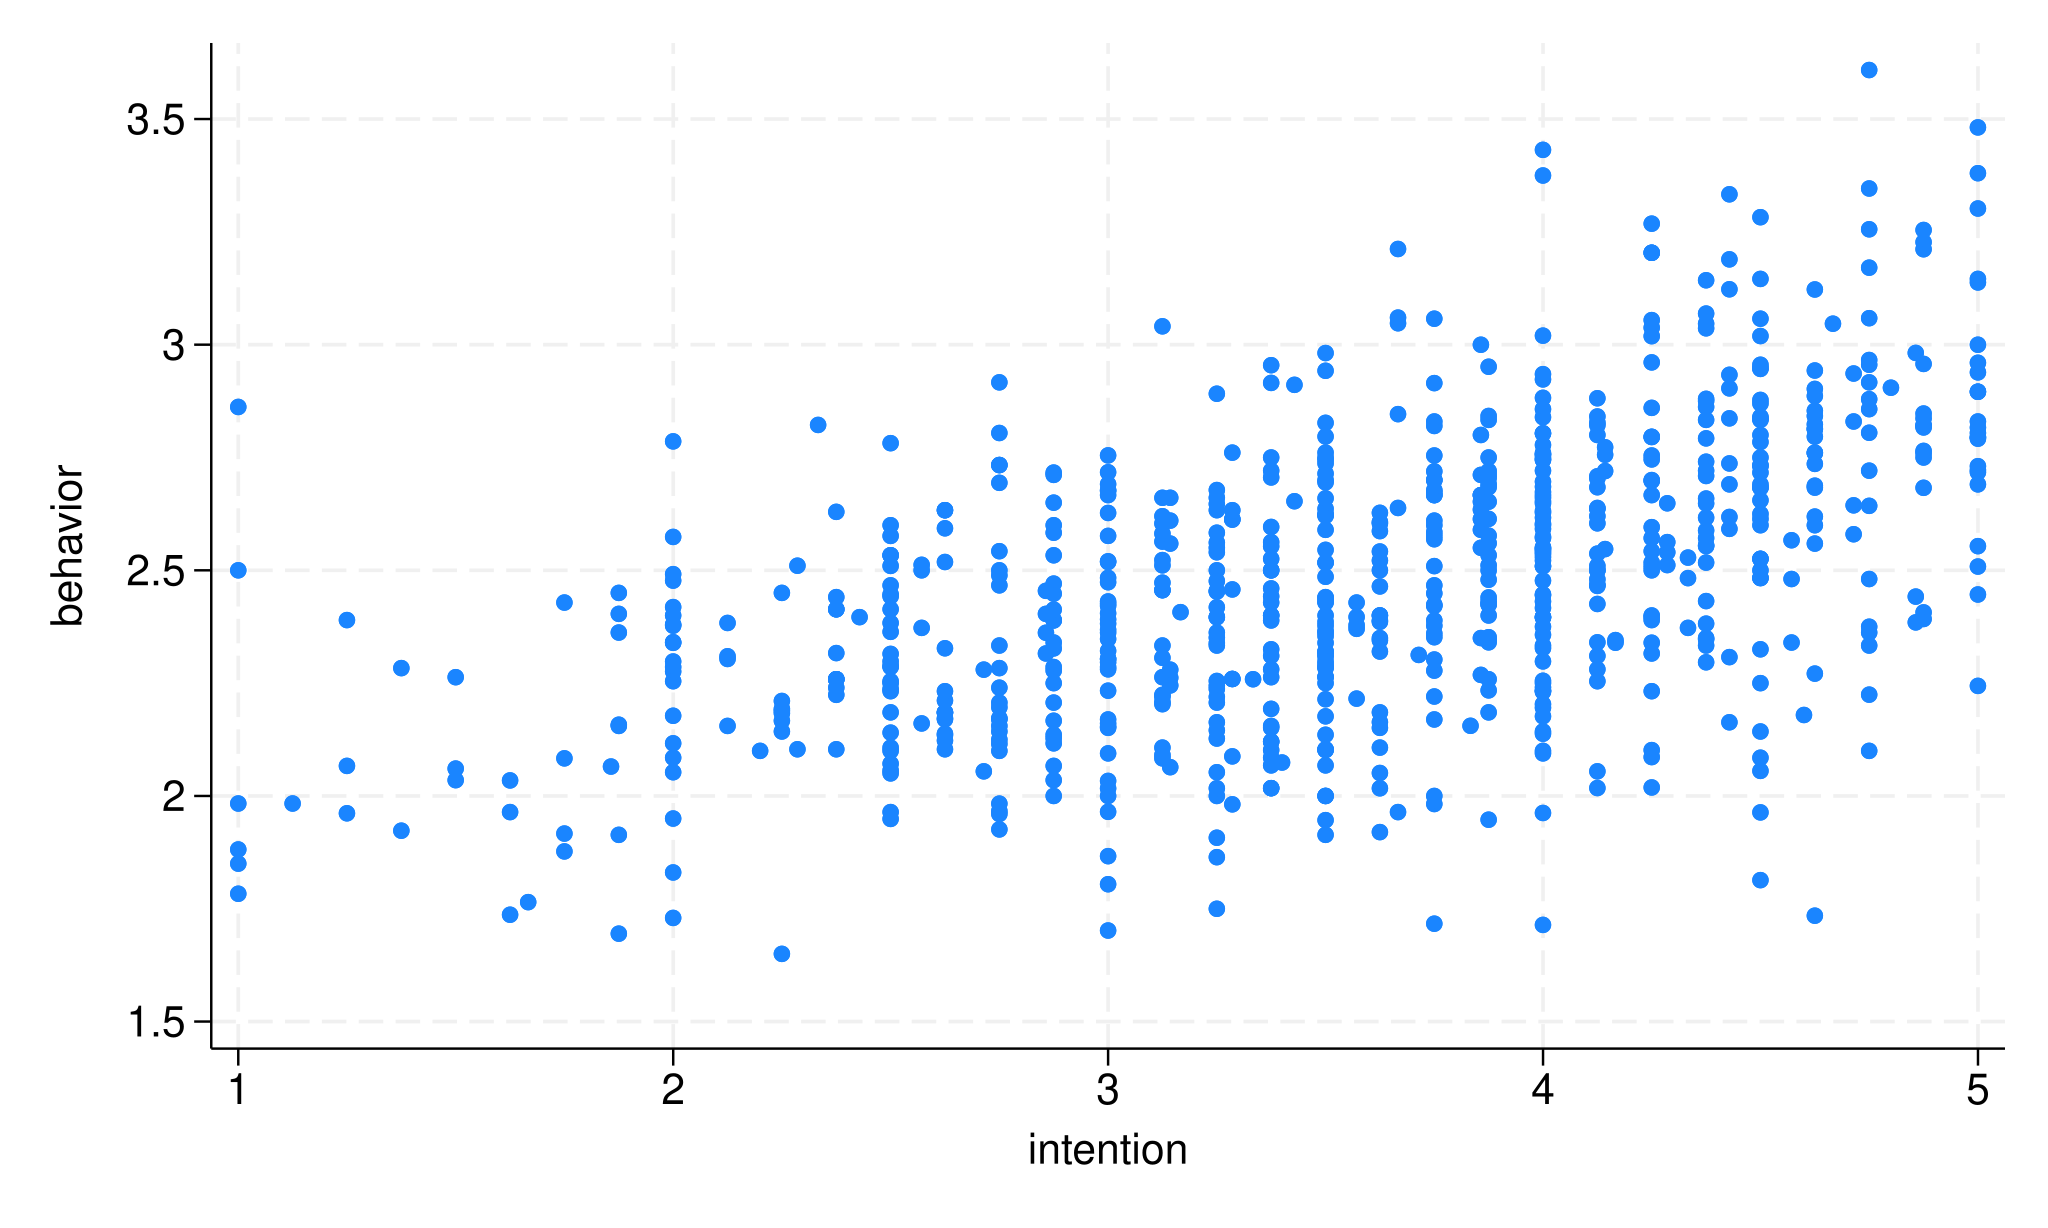

In [101]:
%%stata
scatter behavior intention

## Step 4 - _Perform assumptions check_
In order to have this step correctly executed one must make sure that **the residuals** are subjected by these tests and not the variables themselves.

1. **normality** + **plot** : use tests you're already accustomed to like `swilk` and `sktest`  (kurtosis and skewness)

2. **homoscedasticity**: `estat hettest` to test if hom. holds true (_The null hypothesis is that the data is perfectly homoscedastic._). If not, use HC3 method `vce(hc3)` as *option* in reg analysis

3. **linearity**: `rvfplot` can be used for depicting **unstandardized** residuals vs predictions 
                `predict y, xb` then `scatter e y, mlabel(id) yline(-3 0 3)` to use the std residuals from `predict e, rstandard`


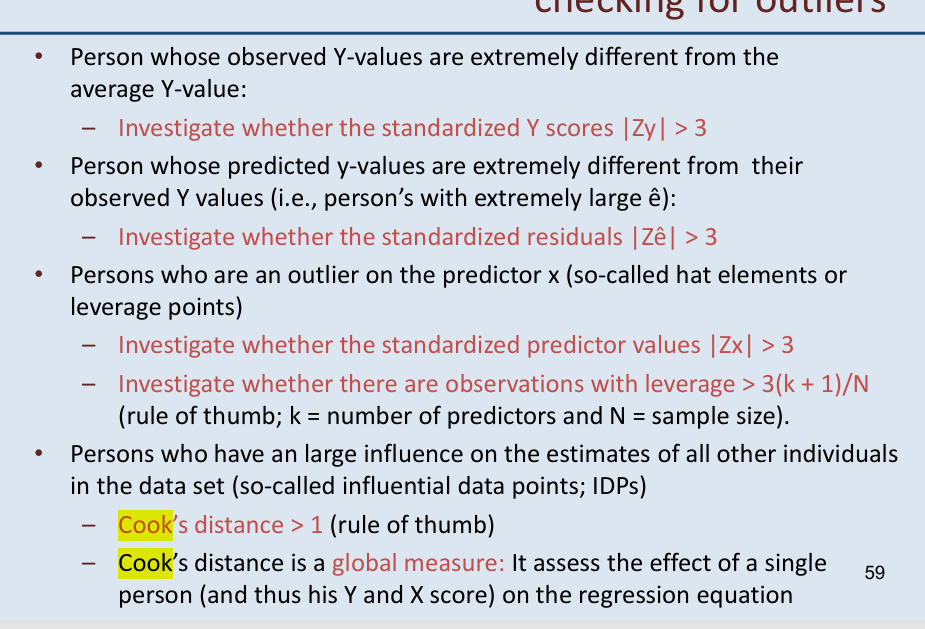


. reg behavior intention

      Source |       SS           df       MS      Number of obs   =       800
-------------+----------------------------------   F(1, 798)       =    315.82
       Model |  22.8714669         1  22.8714669   Prob > F        =    0.0000
    Residual |  57.7910839       798  .072419905   R-squared       =    0.2835
-------------+----------------------------------   Adj R-squared   =    0.2826
       Total |  80.6625508       799  .100954381   Root MSE        =    .26911



------------------------------------------------------------------------------
    behavior | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   intention |    .197782   .0111293    17.77   0.000     .1759358    .2196282
       _cons |   1.771048   .0406943    43.52   0.000     1.691167    1.850928
------------------------------------------------------------------------------

. 
. drop e y

. * NORMALITY
. * first obtain the standardized residuals using the predict postestimation fu
> nction
. * to get more info on what postestimation functions are available for regress
>  tyoe help regress postestimation in the command line
. predict e, rstandard //this post estimation command creates a new variable th
> at I labeled "e" and which contains standardized residuals "stand"

. hist e, norm
(bin=28, start=-3.5399156, width=.24584666)

. swilk  e

                   Shapiro–Wilk W test for normal

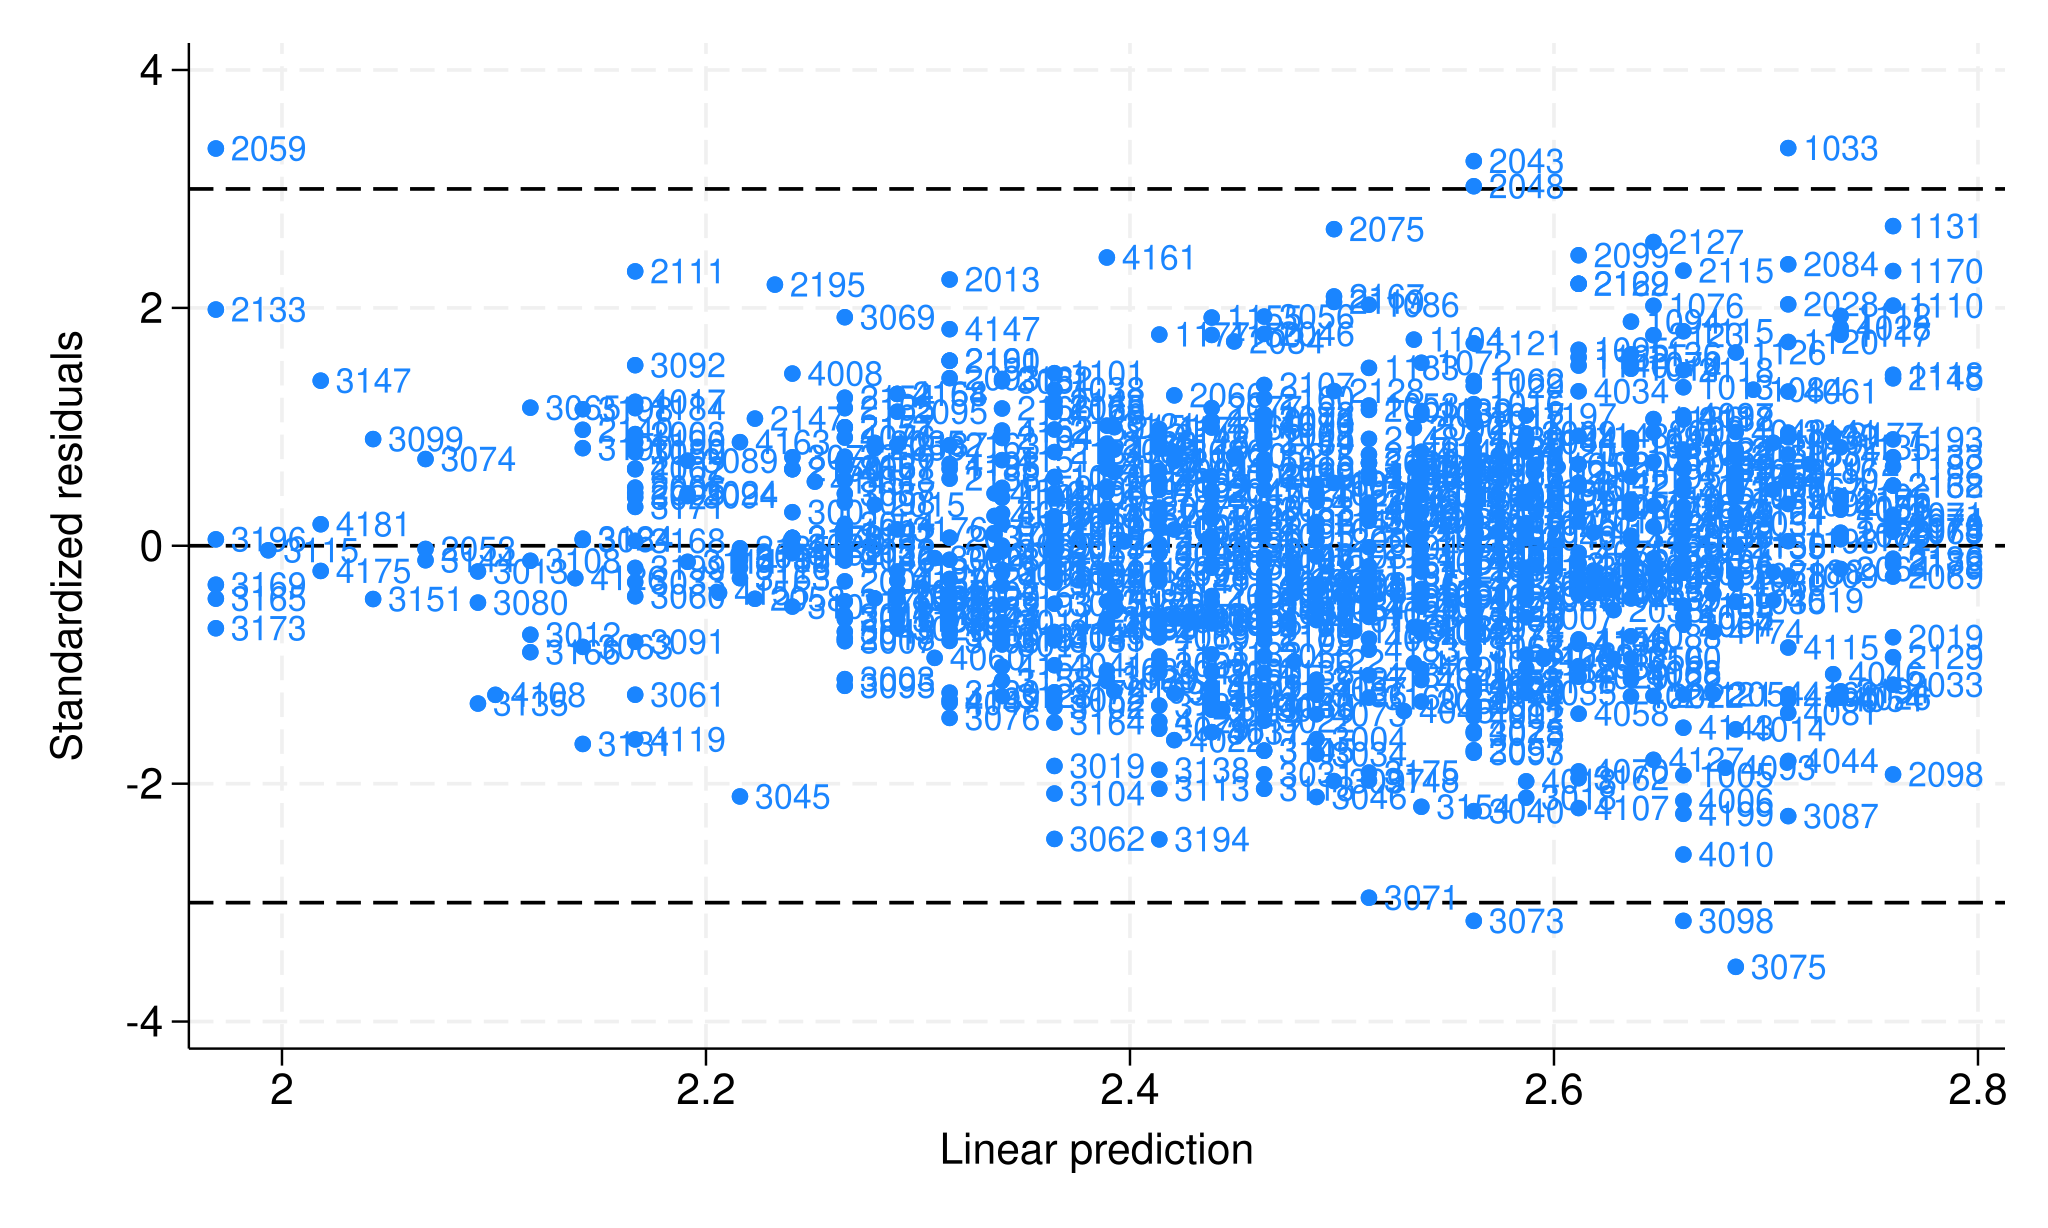

In [ ]:
%%stata
reg behavior intention

drop e y
* NORMALITY
* first obtain the standardized residuals using the predict postestimation function
* to get more info on what postestimation functions are available for regress tyoe help regress postestimation in the command line
predict e, rstandard //this post estimation command creates a new variable that I labeled "e" and which contains standardized residuals "stand"
hist e, norm
swilk  e
sktest e

* LINEARITY HOMOSCEDASTICITY
predict y, xb 
scatter e y, mlabel(id) yline(-3 0 3) // since standardized y>3 or standardized z>3
                                      // rvfplot, mlabel(id) can be also used but it displays a rather unstandardized image of the residuals

* HOMOSCEDASTICITY 
estat hettest



. * Generating the standardized residuals, their corresponding cook distances a
> nd flags yielded by leverage tests
. * then displaying everything
. predict new_var, rstand

. predict new_var_leverage, leverage

. predict new_var_cook, cooksd

. 
. hist new_var ,normal title("Distribution of standardized residuals")
(bin=28, start=-3.5399156, width=.24584666)

. 
. list new_var_cook if new_var_cook>1

. * identifying extreme residuals
. list id new_var if abs(new_var)>3

     +------------------+
     |   id     new_var |
     |------------------|
 33. | 1033    3.343791 |
242. | 2043    3.234126 |
247. | 2048    3.022824 |
258. | 2059    3.340041 |
472. | 3073   -3.153231 |
     |------------------|
474. | 3075   -3.539916 |
497. | 3098   -3.153686 |
     +------------------+

. * identifying leverage points
. list id new_var_leverage if new_var_leverage > 3*(1+1)/801

     +-----------------+
     |   id   new_va~e |
     |-----------------|
252. | 2053   .0084738 |
258. | 2059   .

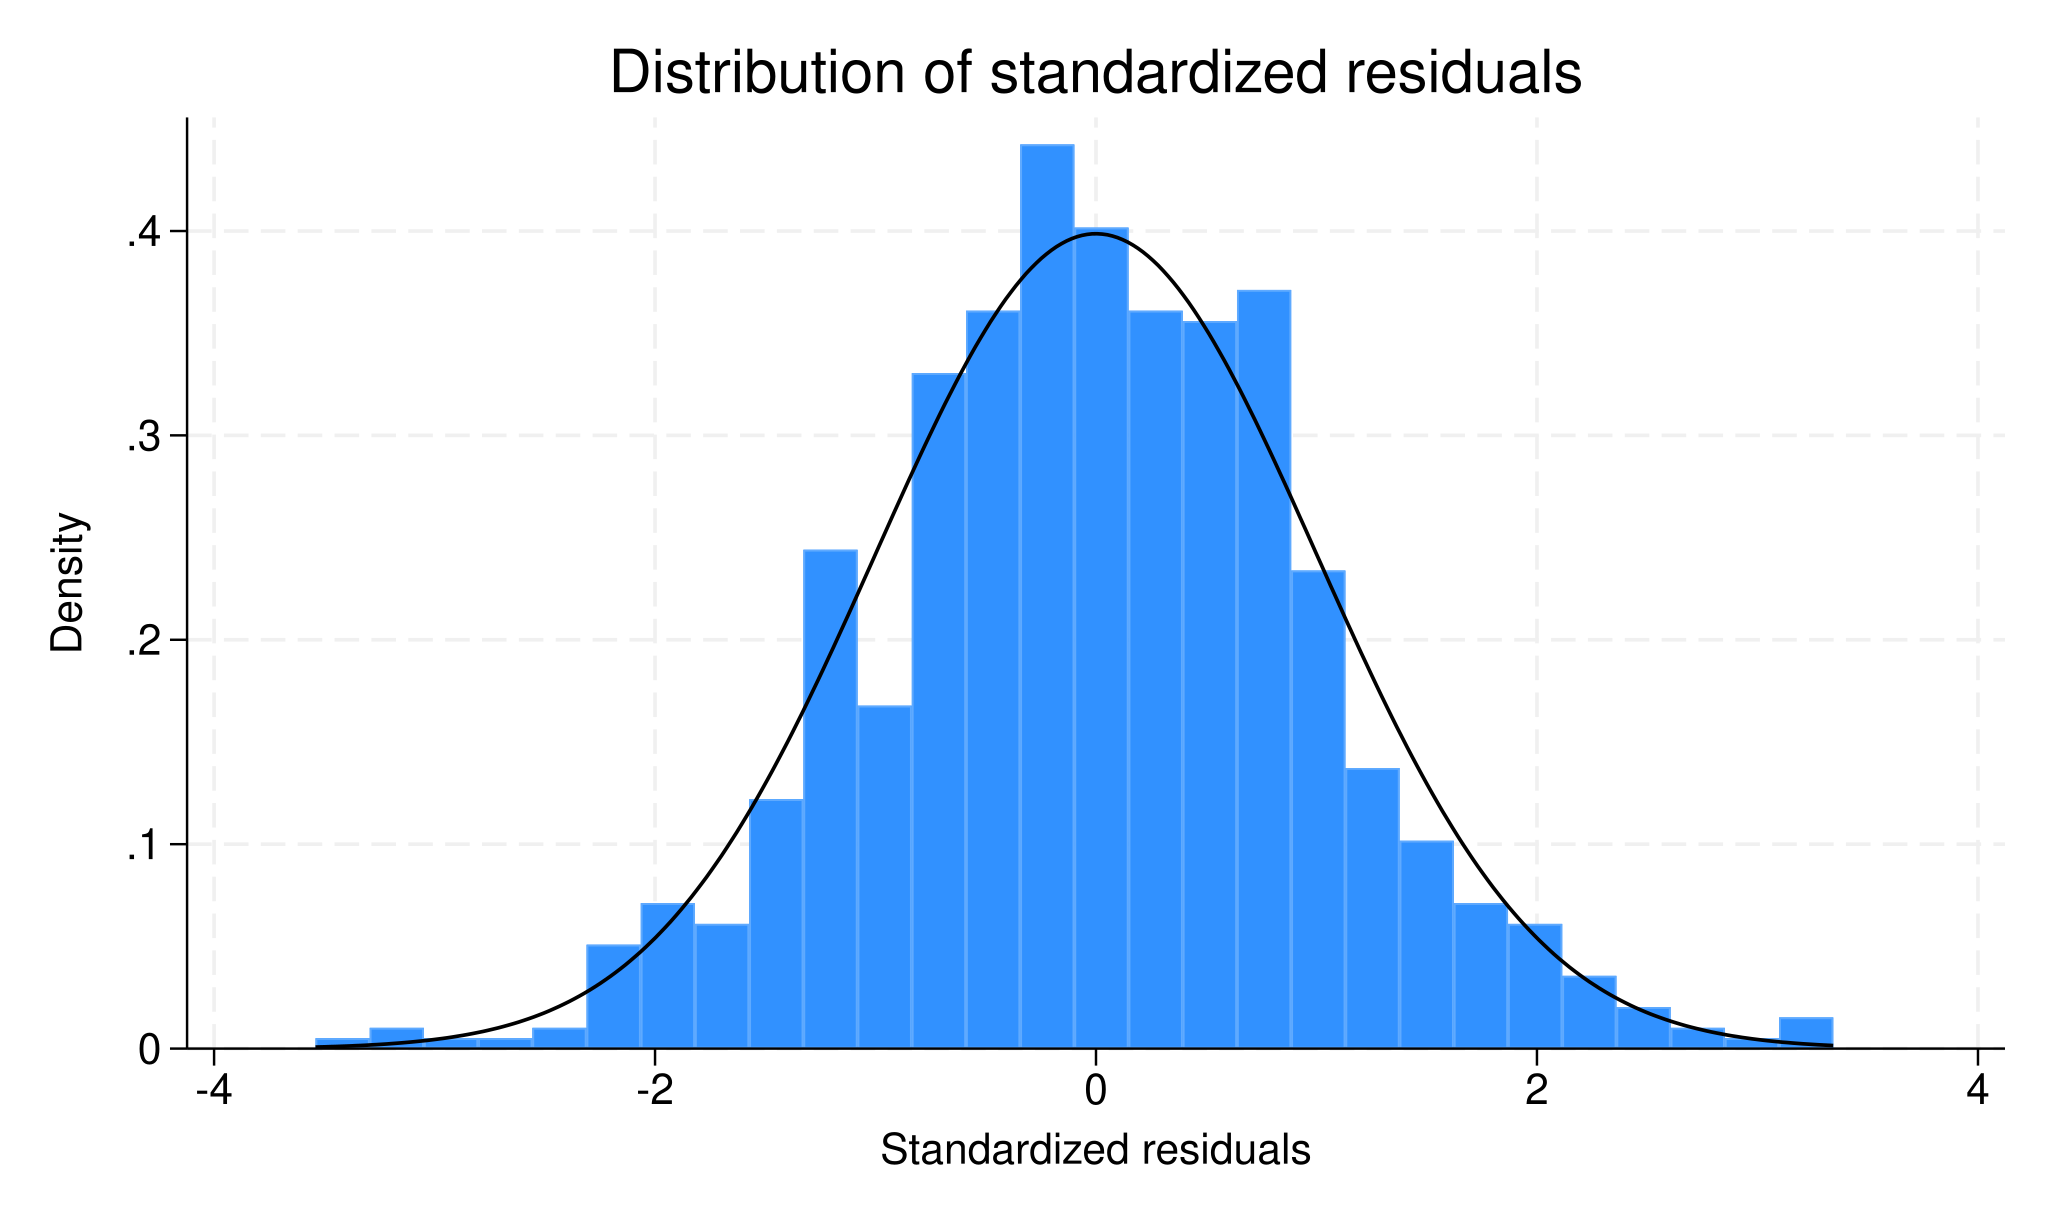

In [110]:
%%stata
* Generating the standardized residuals, their corresponding cook distances and flags yielded by leverage tests
* then displaying everything
predict new_var, rstand
predict new_var_leverage, leverage
predict new_var_cook, cooksd

hist new_var ,normal title("Distribution of standardized residuals")

list new_var_cook if new_var_cook>1
* identifying extreme residuals
list id new_var if abs(new_var)>3
* identifying leverage points
list id new_var_leverage if new_var_leverage > 3*(1+1)/801

gen outliers = (new_var_leverage > 3*(1+1)/801 | abs(new_var) > 3 | new_var_cook > 1) 
list id if outliers==1

## Step 5 - _Correct for disruptions (either assumption violations or disruptive points such as idp)_

In [125]:
%%stata
*run the regression again without outliers to determine whether tests of assumption improve
reg behavior intention if outliers==0
reg behavior intention if outliers==0, vce(hc3)   // uses robust standard errors with the hc3 method


. *run the regression again without outliers to determine whether tests of assu
> mption improve
. reg behavior intention if outliers==0

      Source |       SS           df       MS      Number of obs   =       776
-------------+----------------------------------   F(1, 774)       =    304.78
       Model |  20.3428744         1  20.3428744   Prob > F        =    0.0000
    Residual |  51.6617827       774  .066746489   R-squared       =    0.2825
-------------+----------------------------------   Adj R-squared   =    0.2816
       Total |  72.0046571       775  .092909235   Root MSE        =    .25835

------------------------------------------------------------------------------
    behavior | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   intention |   .2048998   .0117368    17.46   0.000     .1818601    .2279395
       _cons |   1.744032   .0432826    40.29   0.000     1.659066    


Linear regression                               Number of obs     =        776
                                                F(1, 774)         =     301.06
                                                Prob > F          =     0.0000
                                                R-squared         =     0.2825
                                                Root MSE          =     .25835

------------------------------------------------------------------------------
             |             Robust HC3
    behavior | Coefficient  std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   intention |   .2048998    .011809    17.35   0.000     .1817184    .2280812
       _cons |   1.744032   .0423222    41.21   0.000     1.660952    1.827112
------------------------------------------------------------------------------

. 


## Step 6 - _dealing with **multiple regression** (only continuous predictors and ViF)_

In [136]:
%%stata
reg intention attitude social_norms perc_beh_cont
estat vif


. reg intention attitude social_norms perc_beh_cont

      Source |       SS           df       MS      Number of obs   =       797
-------------+----------------------------------   F(3, 793)       =    142.55
       Model |  204.687884         3  68.2292945   Prob > F        =    0.0000
    Residual |  379.557869       793  .478635396   R-squared       =    0.3503
-------------+----------------------------------   Adj R-squared   =    0.3479
       Total |  584.245753       796  .733977076   Root MSE        =    .69183

------------------------------------------------------------------------------
   intention | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
    attitude |   .3226257   .0438049     7.37   0.000     .2366385    .4086129
social_norms |   .2804911   .0287338     9.76   0.000     .2240878    .3368944
perc_beh_c~t |   .2197762   .0371719     5.91   0.000     .1468092    .29274

perc_beh_c~t |      1.46    0.682624
social_norms |      1.31    0.762627
    attitude |      1.25    0.798374
-------------+----------------------
    Mean VIF |      1.34

. 


## Step 7 - _Calculate the semi-partial correlation_
use `pcorr` function to do that

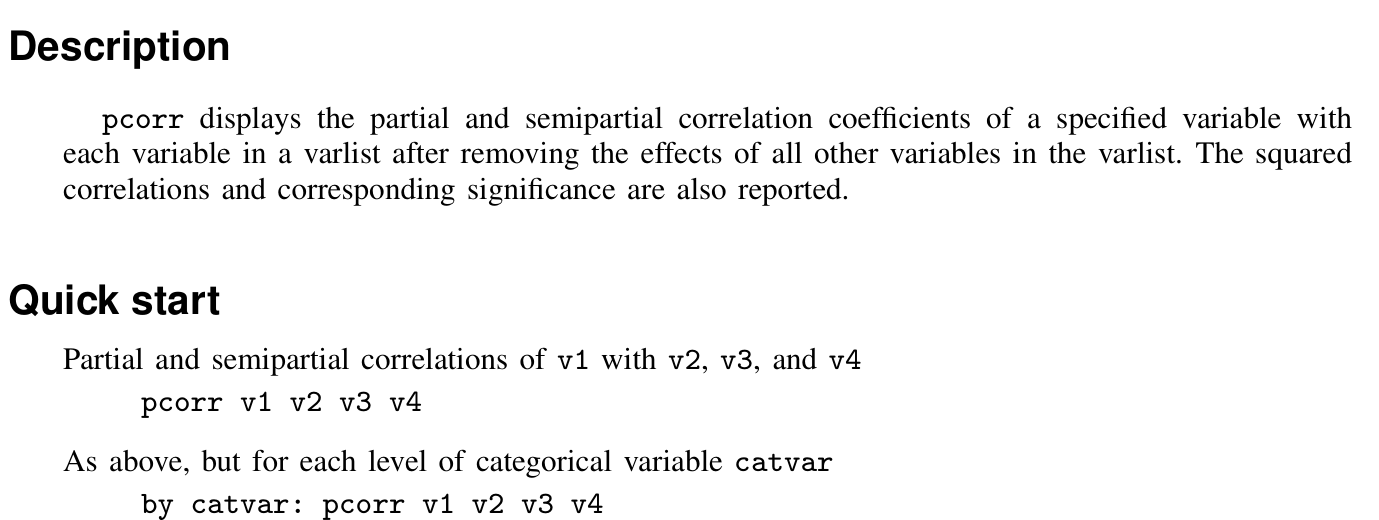

In [138]:
%%stata
pcorr intention attitude social_norms perc_beh_cont

(obs=797)

Partial and semipartial correlations of intention with

               Partial   Semipartial      Partial   Semipartial   Significance
   Variable |    corr.         corr.      corr.^2       corr.^2          value
------------+-----------------------------------------------------------------
   attitude |   0.2530        0.2108       0.0640        0.0444         0.0000
social_no~s |   0.3275        0.2794       0.1073        0.0781         0.0000
perc_beh_~t |   0.2055        0.1692       0.0422        0.0286         0.0000


## Step 8 - _**moderated multiple regression**_ with mean centering
1. Simple regression (entailing only categorical predictors) and a single continous predictor (intention for behavior): Country is _cat_ and interaction is _dv_: **$ Y=B0 + B1*x_intention + B2_D1 + B3_D2 + B4_D3 $** (assuming 4 levels for cat variable)

2.1. **The Baseline Skeleton** 
   * **Formula section:** $Y = \beta_0 + \beta_1 \times \text{predictor (social norms)} + \beta_2 D_1 + \beta_3 D_2 + \beta_4 D_3$
   * **Definition:** *"the baseline skeleton matching the simple regression with one continuous predictor and one categorical predictor."*

2.2 **The Interaction Effects**
   * **Formula section:** $\beta_5 \times \text{predictor (social norms)} \cdot D_1 + \beta_6 \times \text{social-norm} \cdot D_2 + \beta_7 \times \text{social-norm} \cdot D_3$
   * **Definition:** *"the interaction effects"*

In these kind of problems identifying what variable is the prediction is key (which in this case is represented by _social norm_) to understanding what factor do we need to center in association with.


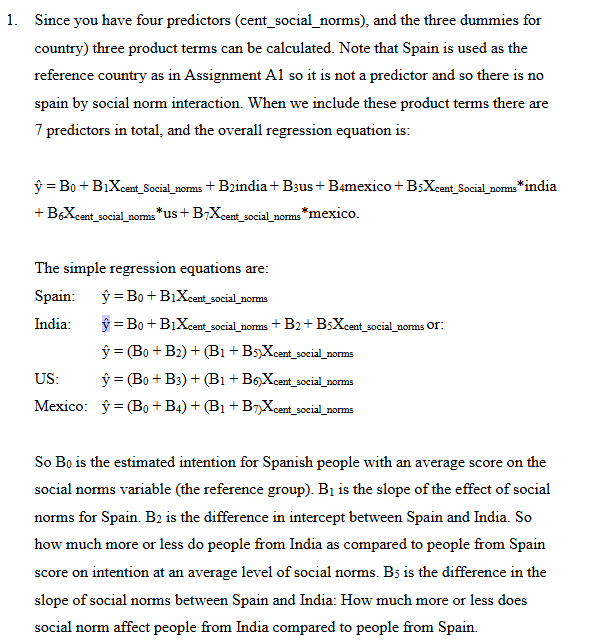

### 8.1 Moderate Multiple regression setup
(centering of the continuous variable) - please use `center` as it is more accurate

In [ ]:
%%stata
*drop missing values listwise
drop if country == . | social_norms == . | intention == .

*creating dummy variables and assign them with proper names
drop spain india us mexico social_norm_centered c_social_norms2
tab country, gen(dummy)
rename dummy1 spain
rename dummy2 india
rename dummy3 us
rename dummy4 mexico

*next center the social_norms variable for example by the egen command
*first find what the mean is
sum social_norms
*and then create a new variable in which the mean is subtracted
gen social_norm_centered = social_norm-3.130028
*or get the mean from the summarize command directly
gen c_social_norms2 = social_norms-r(mean)

*or 
center social_norms, prefix(cent_) //this will mean center the social norms variable giving the new variable the prefic cent_

*next we calculate all the interaction terms
gen cent_social_norms_india = social_norm_centered * india
gen cent_social_norms_spain = social_norm_centered * spain
gen cent_social_norms_us = social_norm_centered * us
gen cent_social_norm_mexic = social_norm_centered * mexico



. *drop missing values listwise
. drop if country == . | social_norms == . | intention == .
(0 observations deleted)

. 
. *creating dummy variables and assign them with proper names
. 
. tab country, gen(dummy)



    country |      Freq.     Percent        Cum.
------------+-----------------------------------
      Spain |        199       24.97       24.97
      India |        200       25.09       50.06
         US |        198       24.84       74.91
     Mexico |        200       25.09      100.00
------------+-----------------------------------
      Total |        797      100.00

. rename dummy1 spain

. rename dummy2 india

. rename dummy3 us

. rename dummy4 mexico

. 
. *next center the social_norms variable for example by the egen command
. *first find what the mean is
. sum social_norms

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
social_norms |        797    3.130028      .97723          1          5

. *and then create a new variable in which the mean is subtracted
. gen social_norm_centered = social_norm-3.130028

. *or get the mean from the summarize command directly
. gen c_soci

### 8.2 Interpretation of the results
The sound arrangement of the standalone predictors and their associated interaction counterparts **must be ensured**. For instance, `india` comes on the third place in this sequence and therefore after declaratrion of categorical predictor levels the first interaction is going to be `cent_social_norms_india`

In [166]:
%%stata
reg intention c_social_norms2 india us mexico cent_social_norms_india cent_social_norms_us cent_social_norm_mexic

*now the simple method. 
*STATA allows to use ANOVA type commands in regression including the ## for a full model with all interaction terms
*country##cent_social_norms will treat country as 3 dummies similar to the i.country (see exercise A of lecture 3)
*but it will also treat cent_social_norms as categorical. Use c. to indicate it is a continuous variable

reg intention c.c_social_norms2##country 


. reg intention c_social_norms2 india us mexico cent_social_norms_india cent_so
> cial_norms_us cent_social_norm_mexic

      Source |       SS           df       MS      Number of obs   =       797
-------------+----------------------------------   F(7, 789)       =     53.15
       Model |  187.207293         7   26.743899   Prob > F        =    0.0000
    Residual |   397.03846       789  .503217312   R-squared       =    0.3204
-------------+----------------------------------   Adj R-squared   =    0.3144
       Total |  584.245753       796  .733977076   Root MSE        =    .70938

------------------------------------------------------------------------------
   intention | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
c_social_n~2 |    .241395   .0683797     3.53   0.000     .1071674    .3756227
       india |  -.6070018   .0805529    -7.54   0.000    -.7651251   -.4488784
         

## Step 9 - _Check whether a slope (perceived as an interaction effect within this case) equals zero_

In [17]:
%%stata
* this can be done by mere replacement of the referenced group category (i.e. Spain -> India)
reg intention c_social_norms2 spain us mexico cent_social_norms_spain cent_social_norms_us cent_social_norm_mexic

*option 2: use margins or test as a post-estimation function on the original model with spain as reference
reg intention c.c_social_norms2##country  

* or other options...
*dydx means slope. So the slope of social norms is test at or for india (coded with a 2)
margins, dydx(c_social_norms2) at(country=(2))

* or using test. Note that the slope of india is the slope of spain (cent_social_norms) + the india by social norms interaction. 
*The i = 2 in i.country means the interaction term for the second level of the country variable

test c_social_norms2 + c.c_social_norms2#2.country = 0


. * this can be done by mere replacement of the referenced group category (i.e.
>  Spain -> India)
. reg intention c_social_norms2 spain us mexico cent_social_norms_spain cent_so
> cial_norms_us cent_social_norm_mexic

      Source |       SS           df       MS      Number of obs   =       797
-------------+----------------------------------   F(7, 789)       =     53.15
       Model |  187.207293         7   26.743899   Prob > F        =    0.0000
    Residual |   397.03846       789  .503217313   R-squared       =    0.3204
-------------+----------------------------------   Adj R-squared   =    0.3144
       Total |  584.245753       796  .733977076   Root MSE        =    .70938

------------------------------------------------------------------------------
   intention | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
c_social_n~2 |   .6089856   .0589299    10.33   0.000     .4933076  


Average marginal effects                                   Number of obs = 797
Model VCE: OLS

Expression: Linear prediction, predict()
dy/dx wrt:  c_social_norms2
At: country = 2

------------------------------------------------------------------------------
             |            Delta-method
             |      dy/dx   std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
c_social_n~2 |   .6089856   .0589299    10.33   0.000     .4933076    .7246636
------------------------------------------------------------------------------

. 
. * or using test. Note that the slope of india is the slope of spain (cent_soc
> ial_norms) + the india by social norms interaction. 
. *The i = 2 in i.country means the interaction term for the second level of th
> e country variable
. 
. test c_social_norms2 + c.c_social_norms2#2.country = 0

 ( 1)  c_social_norms2 + 2.country#c.c_social_norms2 = 0

       F(  1,   789) =  1

## Step 10 - _Centering both, the variable to be moderated and the moderator itself_

### 10.1 Centering part

In [64]:
%%stata
drop intention_centered perc_beh_cont_centered cent_intention_perc_beh_cont

*next center the social_norms variable for example by the egen command
*first find what the means associated to both, predictor and mediator are
sum intention perc_beh_cont

*and then create a new variable assigning the centered values
gen intention_centered = intention-3.556016     
gen perc_beh_cont_centered = perc_beh_cont - 3.712376     

*next we calculate all the interaction terms
gen cent_intention_perc_beh_cont = intention_centered*perc_beh_cont_centered


. drop intention_centered perc_beh_cont_centered cent_intention_perc_beh_cont

. 
. *next center the social_norms variable for example by the egen command
. *first find what the means associated to both, predictor and mediator are
. sum intention perc_beh_cont

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
   intention |        801    3.556016    .8552524          1          5
perc_beh_c~t |        801    3.712376     .798982          1          5

. 
. *and then create a new variable assigning the centered values
. gen intention_centered = intention-3.556016     

. gen perc_beh_cont_centered = perc_beh_cont - 3.712376     

. 
. *next we calculate all the interaction terms
. gen cent_intention_perc_beh_cont = intention_centered*perc_beh_cont_centered

. 


### 10.2 Interpretation part

In [41]:
%%stata
reg behavior intention_centered perc_beh_cont_centered cent_intention_perc_beh_cont


      Source |       SS           df       MS      Number of obs   =       797
-------------+----------------------------------   F(3, 793)       =    120.95
       Model |  25.1031514         3  8.36771712   Prob > F        =    0.0000
    Residual |  54.8609851       793   .06918157   R-squared       =    0.3139
-------------+----------------------------------   Adj R-squared   =    0.3113
       Total |  79.9641365       796  .100457458   Root MSE        =    .26302

------------------------------------------------------------------------------
    behavior | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
intention_~d |   .1704864   .0123293    13.83   0.000     .1462844    .1946883
perc_beh_c~d |   .0736277   .0132536     5.56   0.000     .0476115    .0996439
cent_inten~t |   .0227567   .0116134     1.96   0.050    -.0000399    .0455533
       _cons |   2.468235   .0100035   246.74   0.

## Step 11 - _derive and write down the equations for one standard deviation bellow/above the average_

### Step 11.1 - Identify the predictor that is meant to serve as a refference and determine its standard deviation (**in our case the moderator**)

In [37]:
%%stata
sum perc_beh_cont_centered
* 0.79 round up to .80


. sum perc_beh_cont_centered

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
perc_beh_c~d |        797   -4.29e-07    .7984363   -2.71041    1.28959

. * 0.79 round up to .80
. 


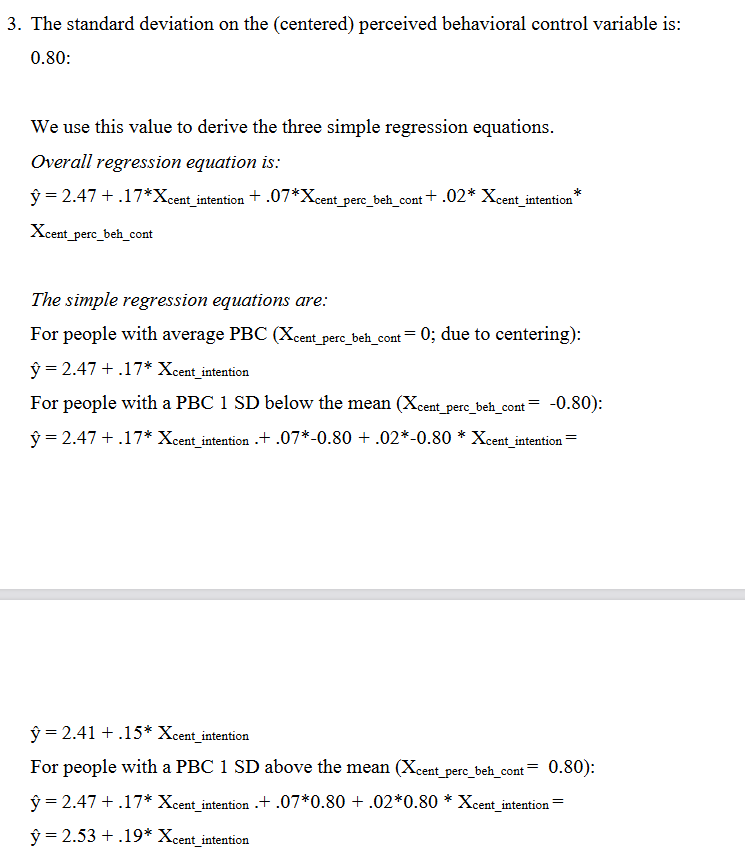

### Step 11.2 - lower the mean/increase the mean with 1SD and run the regression

In [57]:
%%stata
drop low_pbc high_pbc

*first the manual steps for your understading
sum perc_beh_cont //to obtain the SD and the mean
*make mean - 1 SD the reference by creating a new variable centered on mean - 1SD
gen low_pbc = perc_beh_cont - (r(mean) - r(sd))

*alternatively we can add 1 sd to the mean centered variable
* gen low_pbc = perc_beh_cont_centered + r(sd)

*run the regression now with PCB of 1 sd below the mean as reference
reg behavior c.cent_intention##c.low_pbc

*now we do the same for the 1 sd above average PBC

sum perc_beh_cont //to obtain the SD and the mean which is no longer in memory
gen high_pbc = perc_beh_cont - (r(mean) + r(sd))

*run tregressions 
reg behavior c.cent_intention##c.high_pbc


. drop low_pbc high_pbc

. 
. *first the manual steps for your understading
. sum perc_beh_cont //to obtain the SD and the mean

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
perc_beh_c~t |        801    3.712376     .798982          1          5

. *make mean - 1 SD the reference by creating a new variable centered on mean -
>  1SD
. gen low_pbc = perc_beh_cont - (r(mean) - r(sd))

. 
. *alternatively we can add 1 sd to the mean centered variable
. * gen low_pbc = perc_beh_cont_centered + r(sd)
. 
. *run the regression now with PCB of 1 sd below the mean as reference
. reg behavior c.cent_intention##c.low_pbc

      Source |       SS           df       MS      Number of obs   =       801
-------------+----------------------------------   F(3, 797)       =     56.30
       Model |  14.1054311         3  4.70181038   Prob > F        =    0.0000
    Residual |  66.5620048       797   .08351

## 11.3 - Determine whether the mediator brings a significant contribution - use `hireg`

In [68]:
%%stata

*does the interaction add anything statistically significant to the power of prediction?

drop cent_intention cent_perc_beh_cont
center intention perc_beh_cont, prefix(cent_)

gen cent_X_cent = cent_intention * cent_perc_beh_cont

hireg behavior (cent_intention cent_perc_beh_cont) (cent_X_cent)
//hireg does not work with factor based specification (i.e., #)


. 
. *does the interaction add anything statistically significant to the power of 
> prediction?
. 
. drop cent_intention cent_perc_beh_cont

. center intention perc_beh_cont, prefix(cent_)
(generated variables: cent_intention cent_perc_beh_cont)

. 
. gen cent_X_cent = cent_intention * cent_perc_beh_cont

. 
. hireg behavior (cent_intention cent_perc_beh_cont) (cent_X_cent)

Model 1:
   Variables in Model:  
   Adding            : cent_intention cent_perc_beh_cont 

      Source |       SS           df       MS      Number of obs   =       801
-------------+----------------------------------   F(2, 798)       =    177.78
       Model |  24.8639584         2  12.4319792   Prob > F        =    0.0000
    Residual |  55.8034775       798   .06992917   R-squared       =    0.3082
-------------+----------------------------------   Adj R-squared   =    0.3065
       Total |  80.6674359       800  .100834295   Root MSE        =    .26444

----------------------------------------------------

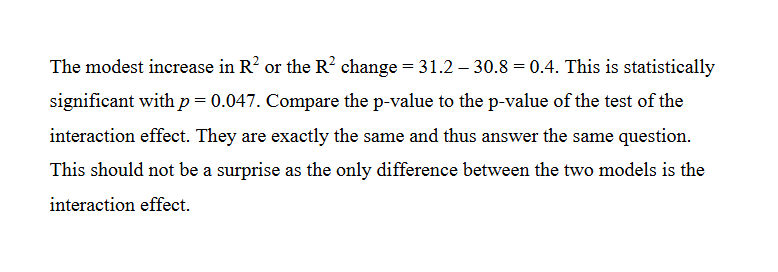